$$
y = f(W_x + b)
$$

Inputs -> [Hidden layer 1] -> [Hidden layer 2] -> Output

In [1]:
import numpy as np
from sklearn.neural_network import MLPClassifier

# Bitwise XOR

| $x_1$ | $x_2$ | $y$ |
|-------|-------|-----|
| 0     | 0     | 0   |
| 0     | 1     | 1   |
| 1     | 0     | 1   |
| 1     | 1     | 0   |

In [2]:
X = np.array([[0, 0],  [0,1], [1,0], [1,1]])
y =np.array([0, 1, 1, 0])

![4 Activation Functions Infographic.png](info.png)

## 1. ReLU (Rectified Linear Unit)

- **Tam adı:** Rectified Linear Unit (Düzləndirilmiş xətti funksiya).
- **Formula:**

$$
f(x) = \max(0,x)
$$

$$
f(x) =
\begin{cases}
0, & x < 0 \\
x, & x \geq 0
\end{cases}
$$

- **Çıxış aralığı:** $[0,+\infty)$
- **İş prinsipi:** Giriş mənfidirsə, $0$ qaytarır. Giriş müsbətdirsə, həmin ədədi dəyişmədən qaytarır.
- **Üstünlükləri:**
  - Sadə və sürətli hesablanır.
  - Dərin neyron şəbəkələrində geniş istifadə olunur.
  - Müsbət girişlərdə *vanishing gradient* problemini azaldır.
- **Çatışmazlığı:** *Dying ReLU* problemi — neyron mənfi girişlərdə davamlı olaraq $0$ qaytara və öyrənməni dayandıra bilər.
- **İstifadəsi:** Əsasən neyron şəbəkələrinin gizli qatlarında (*hidden layers*).

---

## 2. Tanh (Hyperbolic Tangent)

- **Tam adı:** Hyperbolic Tangent (Hiperbolik tangens).
- **Formula:**

$$
\tanh(x) = \frac{e^x-e^{-x}}{e^x+e^{-x}}
$$

- **Çıxış aralığı:** $(-1,1)$
- **İş prinsipi:** Mənfi girişləri mənfi, müsbət girişləri müsbət çıxışlara çevirir. $x=0$ olduqda nəticə $0$-dır.
- **Üstünlükləri:**
  - Çıxışları sıfır ətrafında mərkəzləşir.
  - Sigmoid ilə müqayisədə bəzi hallarda daha səmərəli öyrənmə təmin edir.
  - Həm mənfi, həm də müsbət dəyərləri saxlayır.
- **Çatışmazlığı:** Böyük müsbət və mənfi girişlərdə *vanishing gradient* problemi yaranır.
- **İstifadəsi:** Rekurrent neyron şəbəkələrində (RNN), LSTM modellərində və bəzi gizli qatlarda.

---

## 3. Sigmoid (Logistic Function)

- **Tam adı:** Logistic Sigmoid Function (Logistik sigmoid funksiyası).
- **Formula:**

$$
\sigma(x) = \frac{1}{1+e^{-x}}
$$

- **Çıxış aralığı:** $(0,1)$
- **İş prinsipi:** İstənilən real ədədi $0$ ilə $1$ arasında qiymətə çevirir. $x=0$ olduqda nəticə $0.5$-dir.
- **Üstünlükləri:**
  - Çıxış ehtimal kimi şərh oluna bilər.
  - İkili klassifikasiya üçün əlverişlidir.
  - Davamlı və diferensiallanan funksiyadır.
- **Çatışmazlıqları:**
  - Böyük müsbət və mənfi girişlərdə *vanishing gradient* problemi yaradır.
  - Çıxışı sıfır ətrafında mərkəzləşmir.
- **İstifadəsi:** İkili klassifikasiyada çıxış qatı, logistik reqressiya və LSTM qapıları.

---

## 4. Leaky ReLU (Leaky Rectified Linear Unit)

- **Tam adı:** Leaky Rectified Linear Unit.
- **Formula:**

$$
f(x) = \max(\alpha x,x)
$$

$$
f(x) =
\begin{cases}
\alpha x, & x < 0 \\
x, & x \geq 0
\end{cases}
$$

Burada adətən $\alpha=0.01$ kimi kiçik müsbət qiymət seçilir.

- **Çıxış aralığı:** $(-\infty,+\infty)$, $\alpha>0$ olduqda.
- **İş prinsipi:** Müsbət girişləri dəyişmədən qaytarır. Mənfi girişlər üçün isə sıfır əvəzinə kiçik mənfi qiymətlər qaytarır.
- **Üstünlükləri:**
  - *Dying ReLU* problemini azaltmağa kömək edir.
  - Mənfi girişlərdə də gradientin ötürülməsinə imkan verir.
  - Hesablanması sadədir.
- **Çatışmazlığı:** $\alpha$ parametrinin düzgün seçilməsi vacibdir və hər modeldə adi ReLU-dan daha yaxşı nəticə vermir.
- **İstifadəsi:** Dərin neyron şəbəkələrinin gizli qatlarında, xüsusilə adi ReLU ilə neyronların sönməsi problemi müşahidə edildikdə.

---

## Aktivasiya funksiyalarının müqayisəsi

| Funksiya | Çıxış aralığı | Əsas istifadə sahəsi |
|---|---|---|
| **ReLU** | $[0,+\infty)$ | Gizli qatlar |
| **Tanh** | $(-1,1)$ | RNN, LSTM |
| **Sigmoid** | $(0,1)$ | İkili klassifikasiya |
| **Leaky ReLU** | $(-\infty,+\infty)$ | Gizli qatlar, Dying ReLU probleminin azaldılması |

### Nəticə

Müasir dərin neyron şəbəkələrində:

- **ReLU** — gizli qatlarda ən geniş istifadə olunan aktivasiya funksiyalarından biridir.
- **Tanh** — sıfır mərkəzli çıxış tələb olunan hallarda və rekurrent şəbəkələrdə istifadə edilir.
- **Sigmoid** — ikili klassifikasiyada çıxışın ehtimal kimi interpretasiyası üçün istifadə olunur.
- **Leaky ReLU** — ReLU-nun mənfi girişlərdə sıfır gradient problemini azaltmaq üçün tətbiq edilir.


In [16]:
model = MLPClassifier(hidden_layer_sizes=(4,), max_iter=3000, activation='tanh')
model.fit(X, y)


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(4,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'tanh'
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",3000
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",None


In [17]:
model.predict([[0, 0], [1, 0], [0, 0], [1, 1], [0, 1], [1, 0]])

array([0, 1, 0, 0, 1, 1])

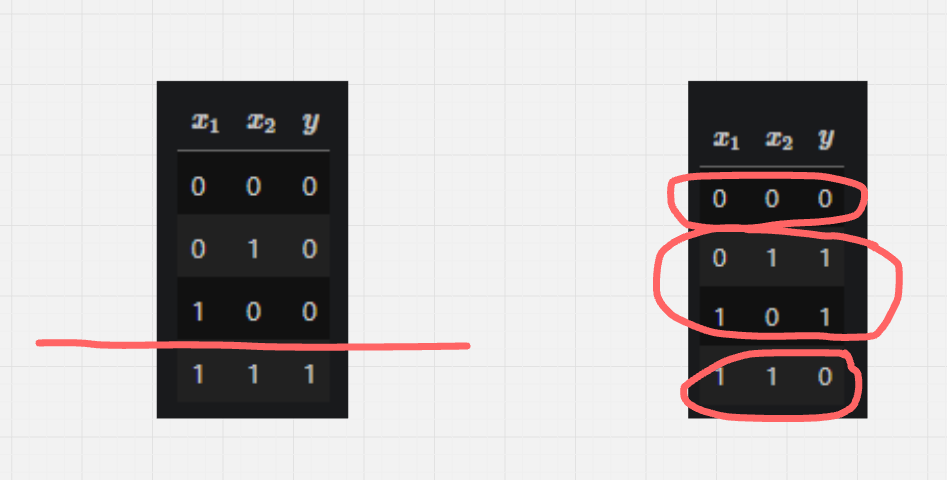